# **Lab 2: Grover's Search Algorithm**

**Duration: 90 minutes.** The theory was covered in the lecture; in this lab you build the two
ingredients of Grover's algorithm (the oracle and the diffuser), assemble the algorithm, and run it
on the simulator.

| Part |
|---|
| Setup |
| Part 1) Searching classically |
| Part 2) The uniform superposition and the geometric picture |
| Part 3) The oracle |
| Part 4) The diffuser |
| Part 5) Grover's algorithm |
| Part 6) How many iterations? |
| Problems 1–4 |

**How to use this notebook**
- **Exercises** — highlighted in yellow boxes. Write your code between the `### FILL YOUR CODE IN HERE` markers in the cell below the exercise text.
- **Check** cells test your code. If they print a success message you can move on; if they raise an error, read the message.
- **Q** — questions are highlighted in green boxes. Answer in the cell below each box.

---

## **Setup**

Run this cell first to check your Python version.

In [1]:
import sys

recommended = (3, 10)
current = sys.version_info[:2]

if current < recommended:
    print(f"You are using Python {current[0]}.{current[1]}. Python {recommended[0]}.{recommended[1]} or later is recommended.")
else:
    print(f"Python {current[0]}.{current[1]} — looks good!")

Python 3.10 — looks good!


Next, run the cell below to install and upgrade the required packages. If the upgrade process causes dependency conflicts with packages already installed in your local environment, __create a new Python environment__ (Python 3.12 recommended) and continue the lab there.

For guidance on setting up a clean environment and installing Qiskit, refer to the IBM Quantum documentation: https://quantum.cloud.ibm.com/docs/guides/install-qiskit

In [2]:
# Install required packages.
# Run this cell the first time you use this notebook (or in a new environment),
# then comment the line below out on subsequent runs.

# %pip install --upgrade 'qiskit[visualization]>=2.5.0' qiskit-aer matplotlib

Once you have installed and upgraded the libraries, please restart the Python kernel and rerun the notebook starting from the Import Libraries cell below.

In [3]:
# Import Libraries
import numpy as np
from IPython.display import display

# Importing standard Qiskit libraries
import qiskit
import qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram
from matplotlib import pyplot as plt

sim = AerSimulator()

def run(qc, shots=1024):
    """Simulate a circuit and return the measurement counts."""
    return sim.run(transpile(qc, sim), shots=shots).result().get_counts()

def amplitudes(qc):
    """Real part of the statevector amplitudes of a circuit (final measurements are ignored)."""
    return np.real(Statevector(qc.remove_final_measurements(inplace=False)).data)

print(f"Qiskit version: {qiskit.__version__}")
print(f"Qiskit Aer version: {qiskit_aer.__version__}")

Qiskit version: 2.5.2
Qiskit Aer version: 0.17.2


Run the next cell. It defines the plotting helpers used throughout the lab — you do not need to read it.

In [4]:
# Plotting helpers (you do not need to read this cell)

def _colors(N, marked):
    return ["crimson" if x in marked else "steelblue" for x in range(N)]

def plot_amplitudes(amps, marked, title, ax=None, mean=None):
    """Bar chart of (real) amplitudes, one bar per basis state x. Solutions are red."""
    ax = ax or plt.figure(figsize=(11, 3)).gca()
    N = len(amps)
    ax.bar(range(N), amps, color=_colors(N, marked))
    ax.axhline(0, color="black", lw=0.8)
    if mean is not None:
        ax.axhline(mean, color="green", ls="--", label=f"mean = {mean:.3f}")
        ax.legend(loc="upper right")
    ax.set_xticks(range(N))
    ax.set_xlabel("basis state $x$")
    ax.set_title(title)

def plot_probabilities(counts, marked, title):
    """Bar chart of measured probabilities, indexed by the integer x. Solutions are red."""
    N = 2 ** len(next(iter(counts)))
    shots = sum(counts.values())
    probs = np.zeros(N)
    for bits, c in counts.items():
        probs[int(bits, 2)] = c / shots
    plt.figure(figsize=(12, 3.5))
    plt.bar(range(N), probs, color=_colors(N, marked))
    plt.xticks(range(N))
    plt.xlabel("measured state $x$")
    plt.ylabel("probability")
    plt.title(title)
    plt.show()

def success_probability(counts, marked):
    """Fraction of the shots in which a solution was measured."""
    shots = sum(counts.values())
    return sum(c for bits, c in counts.items() if int(bits, 2) in marked) / shots

Run the next cell. It defines the check functions — you do not need to read it.

In [5]:
# Check functions (you do not need to read this cell)

def _ideal_oracle(n, marked):
    """The ideal phase oracle V as an Operator: -1 on the marked basis states, +1 on all others."""
    return Operator(np.diag([-1.0 if x in marked else 1.0 for x in range(2**n)]))

def _ideal_diffuser(n):
    N = 2**n
    u = np.ones(N) / np.sqrt(N)
    return Operator(2 * np.outer(u, u) - np.eye(N))

def _flipped_states(U):
    """For a diagonal unitary: which basis states get a relative sign of -1."""
    d = np.diag(U.data)
    d = d * np.conj(d[0])                      # remove the global phase
    flipped = [x for x in range(len(d)) if d[x].real < 0]
    if len(flipped) > len(d) // 2:             # state 0 itself was marked: take the complement
        flipped = [x for x in range(len(d)) if x not in flipped]
    return flipped

def _check_no_measurement(qc, what):
    assert qc.count_ops().get('measure', 0) == 0, f"{what} must not contain a measurement"

def check_classical_search(search):
    import random
    rng = random.Random(1)
    for n in range(2, 7):
        for trial in range(100):
            M = rng.randint(1, 2**n // 2)
            marked = rng.sample(range(2**n), M)
            f = SearchOracle(n, marked)
            x = search(f)
            assert x in f._marked, f"n = {n}, marked = {sorted(f._marked)}: you returned {x!r}, which is not a solution."
            assert f.queries <= 2**n, f"n = {n}: you used {f.queries} queries, but there are only {2**n} candidates."
    print("classical_search always returns a solution")

def check_phase_oracle(make_oracle):
    for n, marked in [(2, [0]), (3, [5]), (4, [3, 6, 13]), (4, [0, 15]), (5, [7, 14, 21, 28])]:
        qc = make_oracle(n, marked)
        assert qc.num_qubits == n, f"phase_oracle({n}, ...) should act on {n} qubits, yours has {qc.num_qubits}"
        _check_no_measurement(qc, "phase_oracle")
        U = Operator(qc)
        if U.equiv(_ideal_oracle(n, marked)):
            continue
        if not np.allclose(U.data, np.diag(np.diag(U.data))):
            raise AssertionError(f"n = {n}, marked = {marked}: the oracle is not diagonal, so it moves basis states "
                                 "instead of only changing their sign. Did you undo every X gate after the MCZ, "
                                 "and put the two H gates on the *target* qubit n-1?")
        raise AssertionError(f"n = {n}, marked = {marked}: your oracle flips the sign of {_flipped_states(U)} "
                             f"instead of {sorted(marked)}. Check which qubits get the X gates (bit j of w is (w >> j) & 1).")
    print("phase_oracle is correct")

def check_kickback_oracle(make_oracle):
    for n, marked in [(2, [0]), (3, [5]), (4, [3, 6, 13]), (4, [0, 15])]:
        qc = make_oracle(n, marked)
        assert qc.num_qubits == n + 1, f"kickback_oracle({n}, ...) should act on {n + 1} qubits (data + ancilla)"
        _check_no_measurement(qc, "kickback_oracle")
        test = QuantumCircuit(n + 1)
        test.h(range(n))
        test.compose(qc, inplace=True)
        sv = Statevector(test).data
        assert np.allclose(sv[2**n:], 0), (f"n = {n}, marked = {marked}: the ancilla q_{n} is not back in |0> "
                                          "at the end. Did you prepare |-> with X then H, and undo it with H then X?")
        expected = np.array([(-1) ** (x in marked) for x in range(2**n)]) / np.sqrt(2**n)
        assert np.allclose(sv[:2**n], expected) or np.allclose(sv[:2**n], -expected), \
            f"n = {n}, marked = {marked}: the data register does not carry the phases (-1)^f(x)."
    print("kickback_oracle is correct: it acts exactly like phase_oracle")

def check_diffuser(make_diffuser):
    for n in (2, 3, 4, 5):
        qc = make_diffuser(n)
        assert qc.num_qubits == n, f"diffuser({n}) should act on {n} qubits, yours has {qc.num_qubits}"
        _check_no_measurement(qc, "diffuser")
        U = Operator(qc)
        if U.equiv(_ideal_diffuser(n)):
            continue
        if U.equiv(_ideal_oracle(n, [0])):
            raise AssertionError(f"n = {n}: your circuit flips only |0...0> - that is the middle part. The H layers are missing.")
        if U.equiv(_ideal_oracle(n, [2**n - 1])):
            raise AssertionError(f"n = {n}: your circuit flips only |1...1> - that is a bare MCZ. The X and H layers are missing.")
        if U.equiv(Operator(np.eye(2**n))):
            raise AssertionError(f"n = {n}: your diffuser does nothing. Did you forget the MCZ in the middle?")
        raise AssertionError(f"n = {n}: the diffuser is not 2|phi><phi| - I. The order is H layer, X layer, MCZ, X layer, H layer.")
    print("diffuser is correct")

def check_grover_circuit(make_circuit):
    n, marked = 4, [3, 6, 13]
    oracle = phase_oracle(n, marked)
    for k, p_expected, tol in [(0, 3 / 16, 0.06), (1, 0.949, 0.05), (2, 0.616, 0.07)]:
        qc = make_circuit(oracle, n, k)
        assert qc.count_ops().get('measure', 0) == n, f"grover_circuit should measure all {n} qubits (qc.measure_all())"
        p = success_probability(run(qc, shots=8192), marked)
        hint = {0: "with 0 iterations the state should be |phi>: a Hadamard on every qubit, nothing else.",
                1: "is the order 'oracle, then diffuser'? Is the diffuser applied on all n qubits?",
                2: "is the loop running `iterations` times, applying the oracle AND the diffuser each time?"}[k]
        assert abs(p - p_expected) < tol, f"k = {k}: P(solution) should be about {p_expected:.2f}, you got {p:.2f} - {hint}"
        print(f"   k = {k}: P(solution) = {p:.3f}  (expected {p_expected:.3f})")
    print("grover_circuit is correct")

def check_optimal_iterations(optimal):
    for N, M, k_expected in [(16, 3, 1), (16, 1, 3), (16, 4, 1), (32, 4, 2), (32, 16, 0), (1024, 1, 25)]:
        theta, k, p = optimal(N, M)
        assert isinstance(k, (int, np.integer)), f"k must be an integer, you returned {k!r} - use int(round(...))"
        assert np.isclose(theta, np.arcsin(np.sqrt(M / N))), f"N = {N}, M = {M}: theta should be arcsin(sqrt(M/N))"
        assert k == k_expected, f"N = {N}, M = {M}: k should be {k_expected}, you returned {k}"
        assert np.isclose(p, np.sin((2 * k + 1) * theta) ** 2), f"N = {N}, M = {M}: P_success should be sin^2((2k+1) theta)"
    print("optimal_iterations is correct")

---

## **The search problem**

We are given a function

$$
f:\{0,1\}^n \to \{0,1\},\qquad
f(x)=\begin{cases}1 & x \text{ is a solution}\\ 0 & \text{otherwise}\end{cases}
$$

as a black box (an **oracle**): we can evaluate $f$, but we know nothing else about it.

There are $N = 2^n$ candidates and $M$ of them are solutions. The task is to **find a solution**.

- **Classically** there is nothing better than trying inputs one after the other: $O(N)$ queries.
- **Grover's algorithm** needs only $O(\sqrt{N/M})$ queries — a *quadratic* speed-up. For $n = 20$ that is about 1 000 instead of 1 000 000.

Throughout the lab we use the running example $n = 4$ ($N = 16$) with the three solutions $x \in \{3, 6, 13\}$.

---

## **Part 1) Searching classically**
### 1.1 A classical black box

`SearchOracle(n, marked)` hides the solutions. You can only call it as `f(x)` with an integer `x` from `0` to `2**n - 1`; it returns `1` for a solution and `0` otherwise, and counts every call in `f.queries`.

(Please don't peek at `f._marked` — that would be opening the box!)

In [6]:
class SearchOracle:
    """Black box for the search problem: f(x) = 1 if x is a solution, else 0. Counts every query."""
    def __init__(self, n, marked):
        self.n, self.N = n, 2**n
        self._marked = set(marked)
        self.queries = 0

    def __call__(self, x):
        self.queries += 1
        return int(x in self._marked)

<div class="alert alert-block alert-warning" style="background-color:#fff3cd; border:1px solid #ffeeba; border-left:6px solid #ffc107; border-radius:4px; padding:12px 16px; color:#856404;">

### Exercise 1: Write a classical search

Write `classical_search(f)` that returns **one** solution, i.e. an integer `x` with `f(x) == 1`. You may only use `f(x)` and `f.N`.

</div>

In [7]:
def classical_search(f):
    """Return an x with f(x) == 1. f.N is the number of candidates (inputs are 0 ... f.N - 1)."""
    # Loop over the candidates x = 0, 1, ..., f.N - 1, query f(x), and return the first x with f(x) == 1.
    ### FILL YOUR CODE IN HERE
    for x in range(f.N):
        if f(x) == 1:
            return x
    ###

In [8]:
# Check
check_classical_search(classical_search)

classical_search always returns a solution


### 1.2 How many queries?

Run your search on 2000 random instances with $N = 16$ and $M = 3$ and look at how many queries it needed.

queries needed: min = 1, mean = 4.26, max = 14


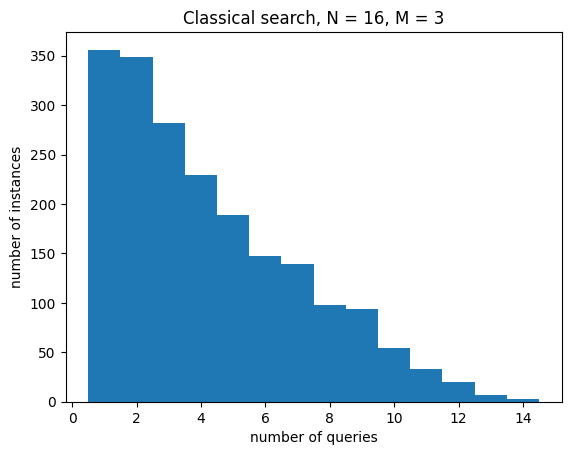

In [9]:
import random

n, M = 4, 3
queries = []
for seed in range(2000):
    marked = random.Random(seed).sample(range(2**n), M)
    f = SearchOracle(n, marked)
    classical_search(f)
    queries.append(f.queries)

print(f"queries needed: min = {min(queries)}, mean = {np.mean(queries):.2f}, max = {max(queries)}")
plt.hist(queries, bins=np.arange(0.5, max(queries) + 1.5))
plt.xlabel("number of queries")
plt.ylabel("number of instances")
plt.title(f"Classical search, N = {2**n}, M = {M}")
plt.show()

<div class="alert alert-block alert-success" style="background-color:#dff0d8; border:1px solid #c3e6cb; border-left:6px solid #28a745; border-radius:4px; padding:12px 16px; color:#155724;">

**Q1.** Our example has $N = 16$ and $M = 3$. *(Keep these numbers in mind: at the end of Part 5 we compare them with Grover's algorithm after one oracle call.)*

**Q1.1** If you are allowed only **one** query, what is the probability that you find a solution?

**Q1.2** How many queries does your search need in the worst case?

</div>

*Your answer:*

**Q1.1** With one query we test one candidate. $M = 3$ of the $N = 16$ candidates are solutions, so the probability of hitting one is $M/N = 3/16 = 0.1875$.

**Q1.2** The worst case is when all $N - M = 13$ non-solutions are tested first. The next query must then be a solution, so the worst case is $N - M + 1 = 14$ queries. This matches `max = 14` in the experiment above. The average was about $4.3$, close to $(N + 1)/(M + 1) = 17/4 = 4.25$.

---

## **Part 2) The uniform superposition and the geometric picture**
### 2.1 The starting state $|\phi\rangle$

Grover's algorithm starts from the equal superposition of **all** candidates,

$$
|\phi\rangle = H^{\otimes n}|0\rangle^{\otimes n} = \frac{1}{\sqrt N}\sum_{x=0}^{N-1}|x\rangle .
$$

Measuring $|\phi\rangle$ is random guessing: every outcome has probability $1/N$.

> **Convention.** Qiskit is *little-endian*: qubit $q_j$ carries bit $j$ of the integer $x$, so the basis state of the integer $w$ has qubit $q_j$ equal to `(w >> j) & 1`.
>
> A counts key like `'1101'` is read as $q_3q_2q_1q_0$, and `int('1101', 2) == 13` is exactly the integer it represents. The helper functions use this everywhere.

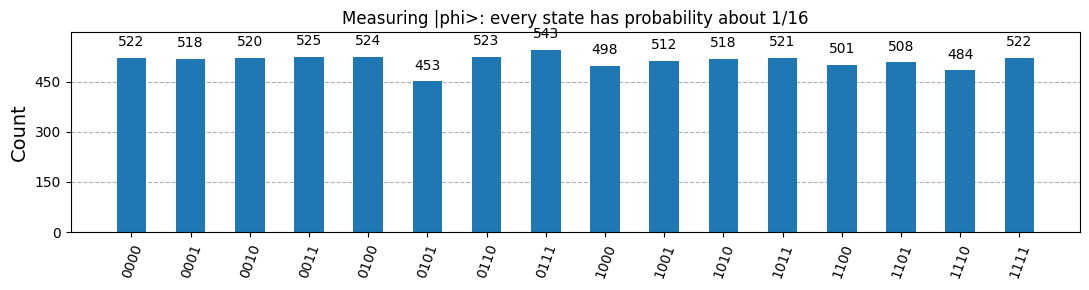

In [10]:
n = 4
qc = QuantumCircuit(n)
qc.h(range(n))          # |phi>
qc.measure_all()
counts = run(qc, shots=8192)
plot_histogram(counts, figsize=(11, 3), title="Measuring |phi>: every state has probability about 1/16")

### 2.2 The geometric picture

Let $|a\rangle$ be the equal superposition of the $M$ solutions and $|a_\perp\rangle$ the equal superposition of the $N - M$ non-solutions. The starting state lies in the plane spanned by these two,

$$
|\phi\rangle = \cos\theta\,|a_\perp\rangle + \sin\theta\,|a\rangle,
\qquad
\sin\theta = \sqrt{\tfrac{M}{N}},
$$

a small angle $\theta$ above the "bad" axis.

In the lecture there was a single target, so $|a\rangle$ was one basis state and $\sin\theta = 1/\sqrt N$. Here we allow $M$ solutions: $|a\rangle$ is their equal superposition, and the only change is $\sin\theta = \sqrt{M/N}$. For $M = 1$ everything below reduces to the lecture.

**Each Grover iteration rotates the state by $2\theta$ toward $|a\rangle$** — that is the whole algorithm. Stop when the state is close to the solution axis and measure.

Run the cell to see the picture.

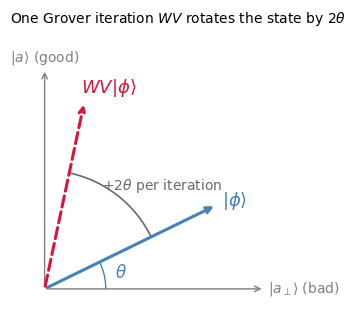

In [11]:
# The geometric picture (run to display)
th = np.deg2rad(26)
fig, ax = plt.subplots(figsize=(4.6, 3.6))
ax.set_aspect("equal"); ax.axis("off")
ax.annotate("", xy=(1.15, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="gray"))
ax.annotate("", xy=(0, 1.15), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="gray"))
ax.text(1.17, 0, r"$|a_\perp\rangle$ (bad)", va="center", fontsize=10, color="gray")
ax.text(0, 1.19, r"$|a\rangle$ (good)", ha="center", fontsize=10, color="gray")
ax.annotate("", xy=(np.cos(th), np.sin(th)), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="steelblue", lw=2.2))
ax.text(np.cos(th) + 0.03, np.sin(th), r"$|\phi\rangle$", color="steelblue", fontsize=13)
ax.annotate("", xy=(np.cos(3*th), np.sin(3*th)), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="crimson", lw=2.2, linestyle="--"))
ax.text(np.cos(3*th) - 0.02, np.sin(3*th) + 0.05, r"$WV|\phi\rangle$", color="crimson", fontsize=13)
a = np.linspace(0, th, 30);       ax.plot(0.32*np.cos(a), 0.32*np.sin(a), color="steelblue", lw=1)
ax.text(0.37, 0.06, r"$\theta$", color="steelblue", fontsize=12)
a = np.linspace(th, 3*th, 40);    ax.plot(0.62*np.cos(a), 0.62*np.sin(a), color="dimgray", lw=1.2)
ax.text(0.30, 0.52, r"$+2\theta$ per iteration", color="dimgray", fontsize=10)
ax.set_xlim(-0.1, 1.5); ax.set_ylim(-0.1, 1.35)
ax.set_title(r"One Grover iteration $WV$ rotates the state by $2\theta$", fontsize=10)
plt.show()

<div class="alert alert-block alert-success" style="background-color:#dff0d8; border:1px solid #c3e6cb; border-left:6px solid #28a745; border-radius:4px; padding:12px 16px; color:#155724;">

**Q2.** For our example ($N = 16$, $M = 3$):

**Q2.1** Compute $\theta$ in degrees.

**Q2.2** By how many degrees does one Grover iteration rotate the state, and where is the state after one iteration?

**Q2.3** How many iterations would you choose?

</div>

*Your answer:*

**Q2.1** $\sin\theta = \sqrt{M/N} = \sqrt{3/16} = 0.433$, so $\theta = \arcsin(0.433) \approx 25.66^\circ$.

**Q2.2** One iteration rotates the state by $2\theta \approx 51.3^\circ$ towards $|a\rangle$. It moves from $\theta \approx 25.7^\circ$ to $3\theta \approx 77.0^\circ$, only $13^\circ$ short of $|a\rangle$. A measurement then gives a solution with probability $\sin^2(3\theta) \approx 0.949$.

**Q2.3** **One** iteration. $k_{\text{opt}} = \operatorname{round}\big(\tfrac{\pi}{4\theta} - \tfrac12\big) = \operatorname{round}(1.25) = 1$. A second iteration would take the state to $5\theta \approx 128^\circ$, past $|a\rangle$, and $P$ would drop to $\sin^2(5\theta) \approx 0.62$.

---

## **Part 3) The oracle**
### 3.1 The phase oracle $V$

Grover's algorithm uses the oracle in the form of a **phase flip** — the operator $V = U_f$ of the lecture: it multiplies every solution by $-1$ and leaves the other states alone,

$$
V|x\rangle = (-1)^{f(x)}|x\rangle
\qquad\Longrightarrow\qquad
V|a_\perp\rangle = |a_\perp\rangle,\quad V|a\rangle = -|a\rangle .
$$

In the 2-D picture this is a **reflection about the bad axis** $|a_\perp\rangle$.

---

**Building $V$ one solution at a time.** Pick one solution and call it $w$; in our example $w$ is one of the integers $3$, $6$, $13$.

We first build a circuit that flips the sign of the single basis state $|w\rangle$ and leaves every other basis state alone. Doing this once for each solution in `marked` gives $V$.

The gate that flips the sign of a single basis state is the **multi-controlled $Z$** (MCZ) on all $n$ qubits: it multiplies $|1\dots1\rangle$ by $-1$ and does nothing to the other $2^n - 1$ basis states.

To flip $|w\rangle$ instead of $|1\dots1\rangle$, sandwich the MCZ between $X$ gates:

1. apply $X$ to every qubit whose bit of $w$ is **0** — this turns $|w\rangle$ into $|1\dots1\rangle$ (and no other state into $|1\dots1\rangle$);
2. apply the MCZ — it flips the sign of this one state;
3. apply the same $X$ gates again — this turns $|1\dots1\rangle$ back into $|w\rangle$.

---

**Worked example: $w = 13$, $n = 4$.** In binary $13 = 1101$. Qiskit is little-endian, so bit $j$ sits on qubit $q_j$:

| qubit | $q_3$ | $q_2$ | $q_1$ | $q_0$ |
|---|---|---|---|---|
| bit of $w = 13$ | 1 | 1 | **0** | 1 |
| step 1 and step 3: $X$ gate? | – | – | **X** | – |

Only $q_1$ gets an $X$. Step 1 turns $|1101\rangle$ into $|1111\rangle$, step 2 multiplies it by $-1$, and step 3 turns it back into $|1101\rangle$, now with a minus sign.

Any other basis state is turned into something other than $|1111\rangle$ in step 1, is untouched by the MCZ, and returns to itself in step 3.

Here is the circuit:

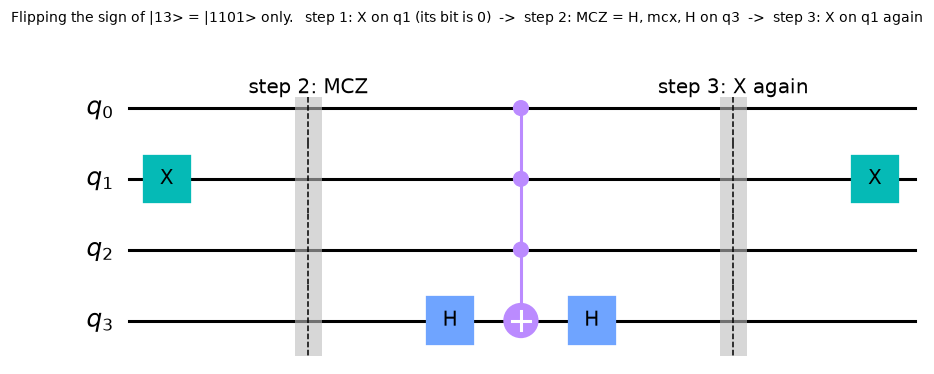

---

Qiskit has no `mcz` gate, but $H X H = Z$, so an MCZ is an `mcx` with an $H$ before and after on the target qubit:

```python
qc.h(n - 1)
qc.mcx(list(range(n - 1)), n - 1)     # controls must be a list
qc.h(n - 1)
```

For several solutions, repeat the X-sandwich once for every $w$ in `marked`.

<div class="alert alert-block alert-warning" style="background-color:#fff3cd; border:1px solid #ffeeba; border-left:6px solid #ffc107; border-radius:4px; padding:12px 16px; color:#856404;">

### Exercise 2: Build the phase oracle

Complete `phase_oracle(n, marked)` so that it flips the sign of every basis state `w` in `marked`. The list `zero_qubits` (the qubits whose bit of `w` is 0) is computed for you.

Hint: use a loop, `for j in zero_qubits: qc.x(j)`. (Qiskit raises an error for `qc.x([])` when the list is empty, which happens for $w = 11\dots1$.)

</div>

In [12]:
def phase_oracle(n, marked):
    """V on n qubits: multiply every |w> with w in `marked` by -1."""
    qc = QuantumCircuit(n, name="Oracle")
    for w in marked:
        zero_qubits = [j for j in range(n) if ((w >> j) & 1) == 0]   # qubits where bit j of w is 0

        # For this w, add the three steps of the X-sandwich:
        #   step 1: X on every qubit in zero_qubits
        #   step 2: MCZ on all n qubits  (h on the target n-1, mcx with the controls as a list, h on the target again)
        #   step 3: X on every qubit in zero_qubits again
        ### FILL YOUR CODE IN HERE
        for j in zero_qubits:                                         # step 1: |w> -> |1...1>
            qc.x(j)
        qc.h(n - 1)                                                   # step 2: MCZ = H . MCX . H on the target
        qc.mcx(list(range(n - 1)), n - 1)
        qc.h(n - 1)
        for j in zero_qubits:                                         # step 3: |1...1> -> |w>
            qc.x(j)
        ###
        qc.barrier()                                                  # only to make the drawing readable
    return qc

phase_oracle is correct


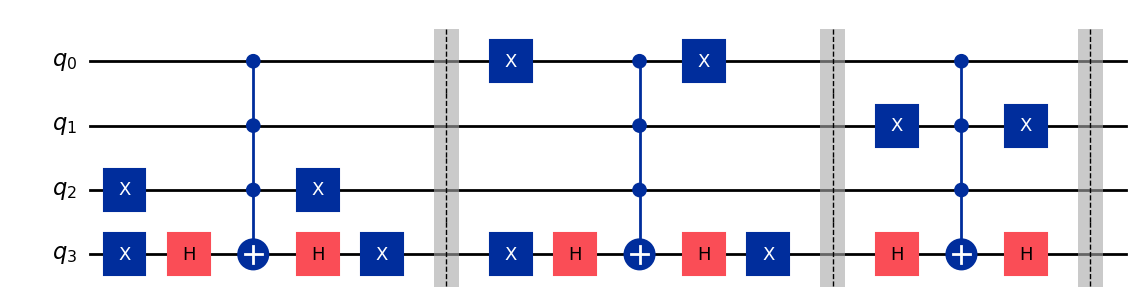

In [13]:
# Check
check_phase_oracle(phase_oracle)
phase_oracle(4, [3, 6, 13]).draw(output='mpl')

Apply your oracle to $|\phi\rangle$ and look at the amplitudes: the solutions should be negative, everything else positive.

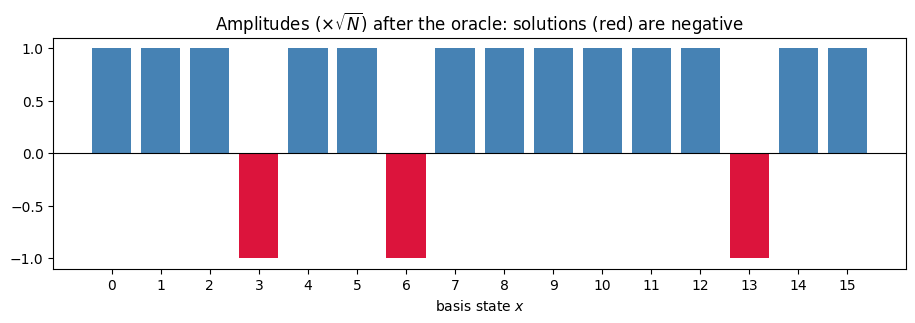

In [14]:
n, marked = 4, [3, 6, 13]
N = 2**n

qc_oracle = QuantumCircuit(n)
qc_oracle.h(range(n))                                   # |phi>
qc_oracle.compose(phase_oracle(n, marked), inplace=True)

plot_amplitudes(amplitudes(qc_oracle) * np.sqrt(N), marked,
                r"Amplitudes ($\times\sqrt{N}$) after the oracle: solutions (red) are negative")
plt.show()

Now add a measurement directly after the oracle and run the circuit.

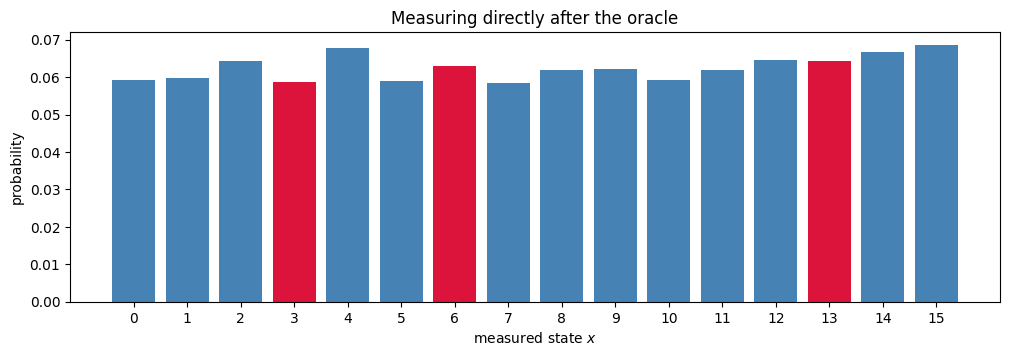

In [15]:
qc = qc_oracle.copy()
qc.measure_all()
plot_probabilities(run(qc, shots=8192), marked, "Measuring directly after the oracle")

<div class="alert alert-block alert-success" style="background-color:#dff0d8; border:1px solid #c3e6cb; border-left:6px solid #28a745; border-radius:4px; padding:12px 16px; color:#155724;">

**Q3.** The histogram above was measured directly after the oracle.

**Q3.1** What does the histogram look like? Compare it with the histogram of $|\phi\rangle$ in Part 2.

**Q3.2** Why does the oracle alone not help us find a solution? *Hint: a measurement only sees the probabilities $|a_x|^2$. What does a sign change do to them?*

</div>

*Your answer:*

**Q3.1** The histogram is flat. Every state, solutions included, has probability about $1/16 = 0.0625$. It looks the same as the histogram of $|\phi\rangle$ in Part 2, within the shot noise.

**Q3.2** The oracle only changes the **sign** of the solutions' amplitudes, $\tfrac{1}{4} \to -\tfrac{1}{4}$. A measurement only sees $|a_x|^2$, and $|-\tfrac14|^2 = |\tfrac14|^2$. So the probabilities are exactly those of $|\phi\rangle$, and measuring now is still random guessing. The information is stored in a relative phase that the measurement cannot see. The diffuser is what turns this sign difference into a difference in magnitude: it reflects every amplitude about the mean, so the negative amplitudes grow and the positive ones shrink.

### 3.2 Relation to the Lab 1 oracle (reading)

In Lab 1 the oracle wrote $f(x)$ into an output qubit, $U_f|x\rangle|y\rangle = |x\rangle|y \oplus f(x)\rangle$.

With the output qubit prepared in $|-\rangle$, phase kickback gives $U_f|x\rangle|-\rangle = (-1)^{f(x)}|x\rangle|-\rangle$ — exactly the phase oracle $V$.

So Grover's oracle is the Lab 1 oracle plus the trick from the Deutsch algorithm; here we simply build $V$ directly.

---

## **Part 4) The diffuser**

The oracle marks the solutions; the **diffuser** $W$ — the *Grover diffusion operator* of the lecture — amplifies them.

It is the reflection about the starting state $|\phi\rangle$, and up to a global phase

$$
W = 2|\phi\rangle\langle\phi| - I = H^{\otimes n}\,X^{\otimes n}\,\mathrm{MCZ}\,X^{\otimes n}\,H^{\otimes n} :
$$

the X-sandwiched MCZ from Part 3 with $w = 0$, between two layers of $H$.

<div class="alert alert-block alert-warning" style="background-color:#fff3cd; border:1px solid #ffeeba; border-left:6px solid #ffc107; border-radius:4px; padding:12px 16px; color:#856404;">

### Exercise 3: Build the diffuser

Complete `diffuser(n)` from the formula above (read it right to left). Build the MCZ as in Exercise 2.

Hint: `qc.h(range(n))` applies H to every qubit.

</div>

In [16]:
def diffuser(n):
    """W = 2|phi><phi| - I  (up to a global phase): reflection about the uniform superposition |phi>."""
    qc = QuantumCircuit(n, name="Diffuser")
    # Add the gates of W = H X MCZ X H, reading the formula from right to left
    # (the rightmost factor is applied first). The MCZ is built as in Exercise 2.
    ### FILL YOUR CODE IN HERE
    qc.h(range(n))
    qc.x(range(n))
    qc.h(n - 1)                          # MCZ = H . MCX . H on the target
    qc.mcx(list(range(n - 1)), n - 1)
    qc.h(n - 1)
    qc.x(range(n))
    qc.h(range(n))
    ###
    return qc

diffuser is correct


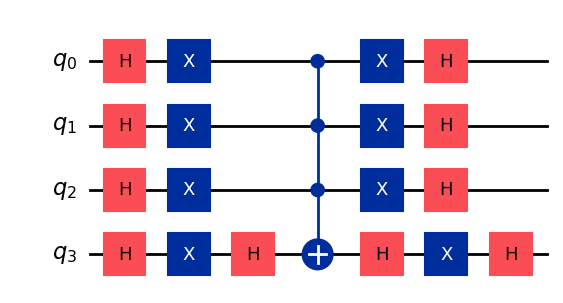

In [17]:
# Check
check_diffuser(diffuser)
diffuser(4).draw(output='mpl')

---

## **Part 5) Grover's algorithm**

One **Grover iteration** is: the oracle, then the diffuser. The oracle is a reflection about $|a_\perp\rangle$, the diffuser a reflection about $|\phi\rangle$, and two reflections make a rotation — by $2\theta$, toward $|a\rangle$ (the derivation is in the appendix).

In formulas the iteration is written $WV$ (first $V$, then $W$); in code it is simply the two sub-circuits appended one after the other.

The full algorithm is

1. prepare $|\phi\rangle = H^{\otimes n}|0\rangle^{\otimes n}$;
2. repeat $k$ times: apply the oracle, then apply the diffuser;
3. measure all qubits.

The oracle is passed in as a circuit, so the same `grover_circuit` works for any oracle, not only for `phase_oracle(n, marked)`.

<div class="alert alert-block alert-warning" style="background-color:#fff3cd; border:1px solid #ffeeba; border-left:6px solid #ffc107; border-radius:4px; padding:12px 16px; color:#856404;">

### Exercise 4: Assemble Grover's algorithm

Complete `grover_circuit(oracle, n, iterations)` following the three steps above; each step has its own block in the cell.

</div>

In [18]:
def grover_circuit(oracle, n, iterations):
    """|phi>, then `iterations` Grover iterations (oracle, then diffuser), then measure all qubits."""
    qc = QuantumCircuit(n)

    # 1. prepare |phi>: a Hadamard on every qubit
    ### FILL YOUR CODE IN HERE
    qc.h(range(n))
    ###

    # 2. repeat `iterations` times: append the oracle, then append the diffuser(n)
    #    (qc.compose(sub, inplace=True) appends a sub-circuit)
    ### FILL YOUR CODE IN HERE
    for _ in range(iterations):
        qc.compose(oracle, inplace=True)
        qc.compose(diffuser(n), inplace=True)
    ###

    # 3. measure all qubits (qc.measure_all())
    ### FILL YOUR CODE IN HERE
    qc.measure_all()
    ###
    return qc

   k = 0: P(solution) = 0.185  (expected 0.188)


   k = 1: P(solution) = 0.950  (expected 0.949)


   k = 2: P(solution) = 0.625  (expected 0.616)
grover_circuit is correct


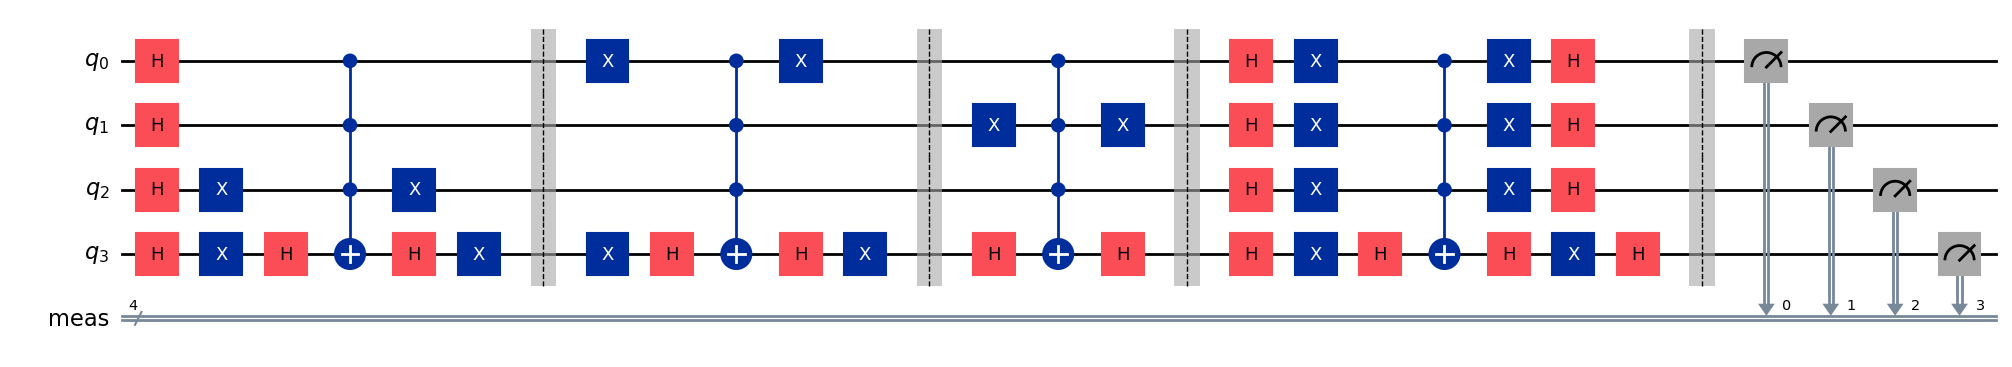

In [19]:
# Check
check_grover_circuit(grover_circuit)
grover_circuit(phase_oracle(4, [3, 6, 13]), 4, 1).draw(output='mpl', fold=-1)

Run the algorithm with **one** iteration on our example and compare with the classical search of Part 1.

P(solution) after ONE oracle call: Grover = 0.947,  classical (one random query) = 0.188


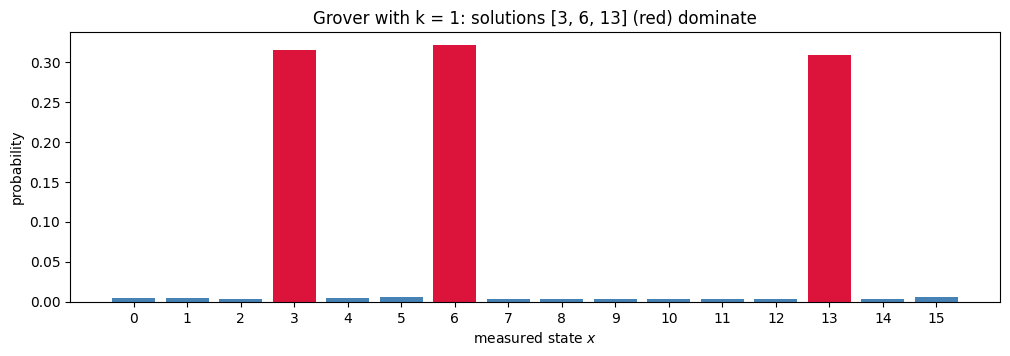

In [20]:
n, marked = 4, [3, 6, 13]
shots = 8192

counts = run(grover_circuit(phase_oracle(n, marked), n, 1), shots=shots)
p = success_probability(counts, marked)
print(f"P(solution) after ONE oracle call: Grover = {p:.3f},  classical (one random query) = {len(marked) / 2**n:.3f}")
plot_probabilities(counts, marked, f"Grover with k = 1: solutions {marked} (red) dominate")

---

## **Part 6) How many iterations?**

After $k$ iterations the state is

$$
\cos\big((2k{+}1)\theta\big)|a_\perp\rangle + \sin\big((2k{+}1)\theta\big)|a\rangle,
\qquad \theta = \arcsin\sqrt{M/N},
$$

so the success probability is $P_k = \sin^2\big((2k{+}1)\theta\big)$.

We want $(2k{+}1)\theta \approx \pi/2$:

$$
k_{\text{opt}} = \operatorname{round}\!\Big(\frac{\pi}{4\theta} - \frac12\Big).
$$

For small $\theta$ this is approximately $\frac{\pi}{4}\sqrt{N/M}$ — the famous square root.

**More is not better:** with too many iterations the state rotates *past* $|a\rangle$ and the probability drops again.

<div class="alert alert-block alert-warning" style="background-color:#fff3cd; border:1px solid #ffeeba; border-left:6px solid #ffc107; border-radius:4px; padding:12px 16px; color:#856404;">

### Exercise 5: Compute the optimal number of iterations

Complete `optimal_iterations(N, M)` so that it returns `(theta, k, p_success)` with $\theta = \arcsin\sqrt{M/N}$, $k = \operatorname{round}(\pi/4\theta - 1/2)$ as an **integer**, and $P = \sin^2((2k+1)\theta)$. Assume $1 \le M \le N$.

Hint: `np.arcsin`, `np.sqrt`, `np.pi`, `int(round(...))`.

</div>

In [21]:
def optimal_iterations(N, M):
    """Return (theta, k, p_success) for N candidates and M solutions."""
    # theta     = arcsin(sqrt(M / N))                 (in radians)
    # k         = round(pi / (4 theta) - 1/2)         as an int
    # p_success = sin^2((2k + 1) theta)
    ### FILL YOUR CODE IN HERE
    theta = np.arcsin(np.sqrt(M / N))
    k = int(round(np.pi / (4 * theta) - 1 / 2))
    p_success = np.sin((2 * k + 1) * theta) ** 2
    ###
    return theta, k, p_success

In [22]:
# Check
check_optimal_iterations(optimal_iterations)

theta, k, p = optimal_iterations(16, 3)
print(f"N = 16, M = 3:  theta = {np.degrees(theta):.2f} deg,  k = {k},  P_success = {p:.4f}")

optimal_iterations is correct
N = 16, M = 3:  theta = 25.66 deg,  k = 1,  P_success = 0.9492


Now compare theory and simulator for $k = 0, 1, \dots, 8$ iterations.

- **Left:** success probability against $k$.
- **Right:** the state in the $(|a_\perp\rangle, |a\rangle)$ plane, one arrow per iteration (solid up to the optimum, dashed beyond it).

k = 0: P(solution) simulator = 0.187   theory = 0.187
k = 1: P(solution) simulator = 0.950   theory = 0.949
k = 2: P(solution) simulator = 0.615   theory = 0.616
k = 3: P(solution) simulator = 0.000   theory = 0.000
k = 4: P(solution) simulator = 0.603   theory = 0.603
k = 5: P(solution) simulator = 0.960   theory = 0.955
k = 6: P(solution) simulator = 0.207   theory = 0.198
k = 7: P(solution) simulator = 0.176   theory = 0.177
k = 8: P(solution) simulator = 0.944   theory = 0.943


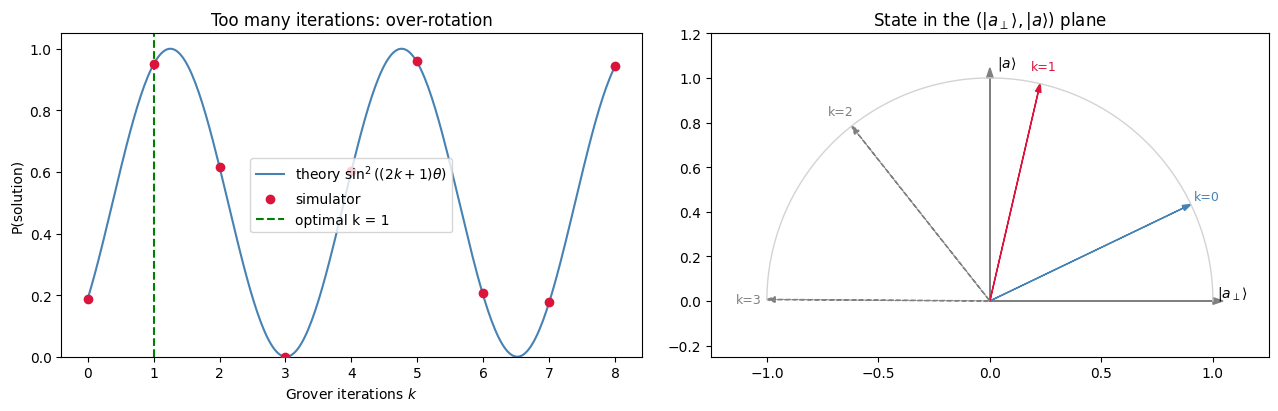

In [23]:
n, marked = 4, [3, 6, 13]
N, M = 2**n, len(marked)
theta, k_opt, _ = optimal_iterations(N, M)
oracle = phase_oracle(n, marked)

ks = range(9)
p_measured = [success_probability(run(grover_circuit(oracle, n, k), shots=4096), marked) for k in ks]
for k, p in zip(ks, p_measured):
    print(f"k = {k}: P(solution) simulator = {p:.3f}   theory = {np.sin((2*k + 1) * theta)**2:.3f}")

fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 4.2))

# Left: probability against the number of iterations
k_fine = np.linspace(0, max(ks), 300)
axL.plot(k_fine, np.sin((2*k_fine + 1) * theta)**2, color="steelblue", label=r"theory $\sin^2((2k+1)\theta)$")
axL.scatter(list(ks), p_measured, color="crimson", zorder=3, label="simulator")
axL.axvline(k_opt, color="green", ls="--", label=f"optimal k = {k_opt}")
axL.set_xlabel("Grover iterations $k$"); axL.set_ylabel("P(solution)"); axL.set_ylim(0, 1.05)
axL.set_title("Too many iterations: over-rotation"); axL.legend()

# Right: the state vector in the 2-D plane
axR.set_aspect("equal"); axR.set_title(r"State in the $(|a_\perp\rangle,|a\rangle)$ plane")
k_show = k_opt + 2
arc = np.linspace(0, (2*k_show + 1) * theta, 200)
axR.plot(np.cos(arc), np.sin(arc), color="lightgray", lw=1)
axR.arrow(0, 0, 1, 0, head_width=0.03, color="gray"); axR.text(1.02, 0.02, r"$|a_\perp\rangle$")
axR.arrow(0, 0, 0, 1, head_width=0.03, color="gray"); axR.text(0.03, 1.05, r"$|a\rangle$")
for k in range(k_show + 1):
    ang = (2*k + 1) * theta
    color, style = ("crimson", "-") if k == k_opt else ("steelblue", "-") if k < k_opt else ("gray", "--")
    axR.arrow(0, 0, np.cos(ang), np.sin(ang), head_width=0.025, color=color, linestyle=style, length_includes_head=True)
    axR.text(1.08*np.cos(ang), 1.08*np.sin(ang), f"k={k}", color=color, fontsize=9, ha="center", va="center")
axR.set_xlim(-1.25, 1.25); axR.set_ylim(-0.25, 1.2)
plt.tight_layout()
plt.show()

<div class="alert alert-block alert-success" style="background-color:#dff0d8; border:1px solid #c3e6cb; border-left:6px solid #28a745; border-radius:4px; padding:12px 16px; color:#155724;">

**Q4.** Read off the left plot.

**Q4.1** What is $P(\text{solution})$ for $k = 2$ and for $k = 3$?

**Q4.2** For which $k > 1$ does the probability become high again, and why?

</div>

*Your answer:*

**Q4.1** $k = 2$: $P = \sin^2(5\theta) \approx 0.62$, since the state has over-rotated to $\approx 128^\circ$. $k = 3$: $P = \sin^2(7\theta) \approx 0.000$, since the state is at $7\theta \approx 179.6^\circ$, almost exactly $-|a_\perp\rangle$, so there is no solution component left.

**Q4.2** It becomes high again at **$k = 5$**, with $P = \sin^2(11\theta) \approx 0.955$, and again at **$k = 8$**, with $P = \sin^2(17\theta) \approx 0.943$. Each iteration keeps rotating by the same $2\theta \approx 51.3^\circ$, so the state goes round the circle in the $(|a_\perp\rangle, |a\rangle)$ plane. $P = \sin^2\big((2k+1)\theta\big)$ is periodic, and it is large whenever the angle is close to $90^\circ$ *or* $270^\circ$: the state $-|a\rangle$ gives the same probabilities as $|a\rangle$ (a global sign).
- At $k = 5$: $11\theta \approx 282^\circ$, near $270^\circ$.
- At $k = 8$: $17\theta \approx 436^\circ = 360^\circ + 76^\circ$, near $90^\circ$ again.

These later peaks need more oracle calls for no gain, so $k = 1$ remains the best choice.

---

## **Problems 1–4**

The oracle is the **only** place where the problem enters; everything else is problem-independent.

The function below combines your pieces into one search:

- takes a Python predicate on $n$-bit integers,
- builds the oracle from its solutions,
- picks $k$ with `optimal_iterations`,
- runs `grover_circuit` and reports the result.

Run the cell — there is nothing to fill in.

In [24]:
def grover_search(predicate, n, shots=4096):
    """Run Grover's algorithm for the solutions of `predicate` on n-bit integers.
    Returns (marked, k, p_theory, p_measured, counts)."""
    N = 2**n
    marked = [x for x in range(N) if predicate(x)]                 # the solutions
    theta, k, p_theory = optimal_iterations(N, len(marked))        # how many iterations
    counts = run(grover_circuit(phase_oracle(n, marked), n, k), shots=shots)
    p_measured = success_probability(counts, marked)
    return marked, k, p_theory, p_measured, counts

# the running example must come out as before
marked, k, p_theory, p_measured, counts = grover_search(lambda x: x in (3, 6, 13), 4)
print(f"running example: k = {k}, P_theory = {p_theory:.3f}, P_measured = {p_measured:.3f}")

running example: k = 1, P_theory = 0.949, P_measured = 0.949


Run the cell below. It applies `grover_search` to four predicates on 5-bit integers ($N = 32$) and plots the histogram of each.

Problem 1 (multiples of 5): M =  7, k = 1, P_theory = 0.988, P_measured = 0.985


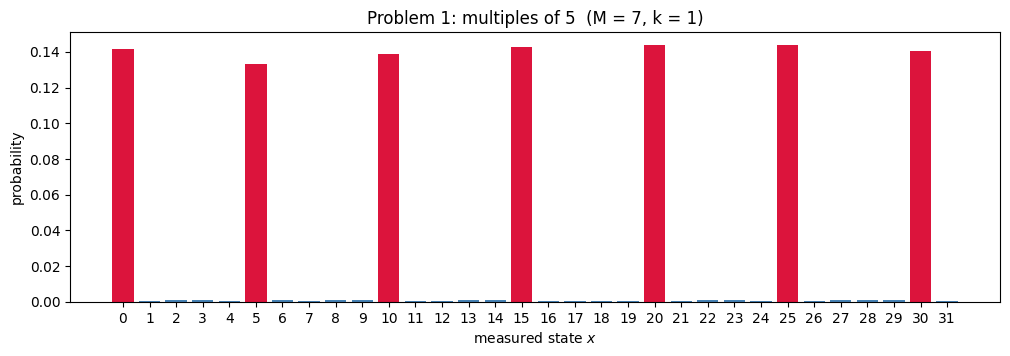

Problem 2 (exactly three 1-bits): M = 10, k = 1, P_theory = 0.957, P_measured = 0.962


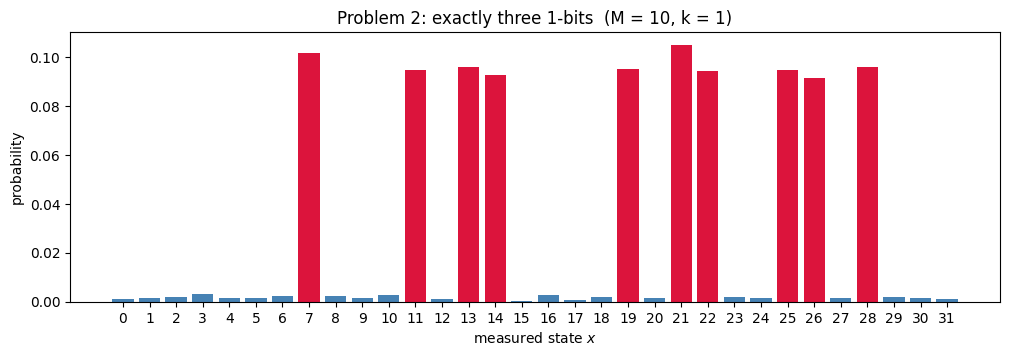

Problem 3 (perfect squares): M =  6, k = 1, P_theory = 0.949, P_measured = 0.949


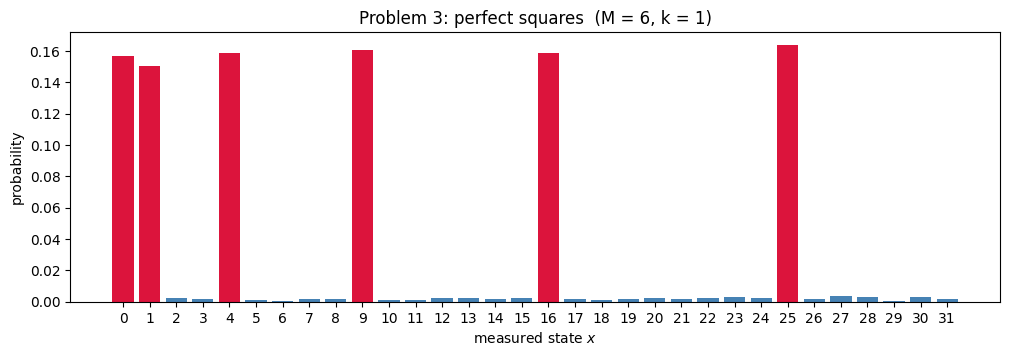

Problem 4 (x >= 16): M = 16, k = 0, P_theory = 0.500, P_measured = 0.501


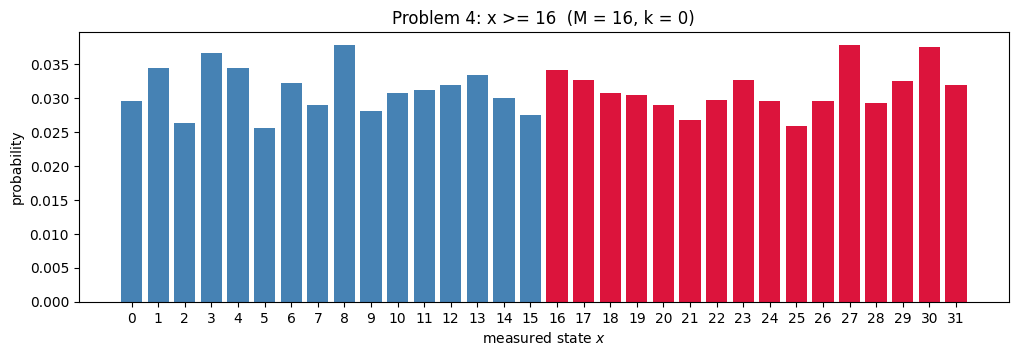

In [25]:
n = 5
problems = {
    1: ("multiples of 5",          lambda x: x % 5 == 0),
    2: ("exactly three 1-bits",    lambda x: bin(x).count("1") == 3),
    3: ("perfect squares",         lambda x: int(np.sqrt(x)) ** 2 == x),
    4: ("x >= 16",                 lambda x: x >= 16),
}

for number, (name, predicate) in problems.items():
    marked, k, p_theory, p_measured, counts = grover_search(predicate, n)
    print(f"Problem {number} ({name}): M = {len(marked):2d}, k = {k}, P_theory = {p_theory:.3f}, P_measured = {p_measured:.3f}")
    plot_probabilities(counts, marked, f"Problem {number}: {name}  (M = {len(marked)}, k = {k})")

The results (the measured values vary slightly from run to run):

| Problem | predicate | $M$ | $k$ | $P_{\text{theory}}$ | $P_{\text{measured}}$ |
|---|---|---|---|---|---|
| 1 | multiples of 5 | 7 | 1 | 0.988 | ≈ 0.99 |
| 2 | exactly three 1-bits | 10 | 1 | 0.957 | ≈ 0.96 |
| 3 | perfect squares | 6 | 1 | 0.949 | ≈ 0.95 |
| 4 | $x \ge 16$ | 16 | 0 | 0.500 | ≈ 0.50 |

**Problem 4 stands out:** $k = 0$ and $P = 1/2$, no better than guessing.

To see what is going on, run the cell below. It keeps $N = 32$ and varies the number of solutions $M = 1, 2, 4, 8, 16$ (the solutions are simply the integers $x < M$).

For comparison it also prints the average number of queries of the classical search from Part 1, which is about $(N+1)/(M+1)$.

In [26]:
n = 5
N = 2**n
print(f"{'M':>3} {'theta':>7} {'k':>3} {'P_theory':>9} {'P_measured':>11} {'classical avg queries':>22}")
for M in (1, 2, 4, 8, 16):
    marked, k, p_theory, p_measured, counts = grover_search(lambda x: x < M, n)
    theta = np.degrees(np.arcsin(np.sqrt(M / N)))
    print(f"{M:>3} {theta:>6.1f}° {k:>3} {p_theory:>9.3f} {p_measured:>11.3f} {(N + 1) / (M + 1):>22.1f}")

  M   theta   k  P_theory  P_measured  classical avg queries


  1   10.2°   4     0.999       1.000                   16.5


  2   14.5°   3     0.961       0.960                   11.0


  4   20.7°   2     0.945       0.947                    6.6


  8   30.0°   1     1.000       1.000                    3.7


 16   45.0°   0     0.500       0.502                    1.9


<div class="alert alert-block alert-success" style="background-color:#dff0d8; border:1px solid #c3e6cb; border-left:6px solid #28a745; border-radius:4px; padding:12px 16px; color:#155724;">

**Q5.** Look at the table above ($N = 32$).

**Q5.1** What happens to the number of iterations $k$ as $M$ grows? Why? *(Think of $\theta$.)*

**Q5.2** For $M = 16$: what is $\theta$, and by how many degrees does one iteration rotate the state? Explain why Grover's algorithm cannot do better than $P = 1/2$ here.

**Q5.3** Compare $k$ with the classical average number of queries. For which kind of search problem is Grover's algorithm worth using?

</div>

*Your answer:*

**Q5.1** $k$ **decreases** as $M$ grows: $4, 3, 2, 1, 0$ for $M = 1, 2, 4, 8, 16$. The starting angle $\theta = \arcsin\sqrt{M/N}$ grows with $M$ ($10.2^\circ \to 45^\circ$), so $|\phi\rangle$ starts closer to $|a\rangle$. Each iteration also rotates by a bigger step $2\theta$, so fewer steps are needed to reach $90^\circ$: $k \approx \tfrac{\pi}{4}\sqrt{N/M}$.

**Q5.2** $\theta = \arcsin\sqrt{16/32} = 45^\circ$, and one iteration rotates by $2\theta = 90^\circ$. The state is reachable only at the angles $(2k+1)\cdot 45^\circ = 45^\circ, 135^\circ, 225^\circ, \dots$. Every one of these is an odd multiple of $45^\circ$, so $P = \sin^2\big((2k+1)45^\circ\big) = \tfrac12$ for **every** $k$. The rotation step is too coarse to ever land on $|a\rangle$: one iteration jumps from $45^\circ$ straight over $90^\circ$ to $135^\circ$. $k = 0$ (just measuring $|\phi\rangle$) is therefore already as good as it gets, and that is plain random guessing, since half of all inputs are solutions.

**Q5.3** For $M = 1$, Grover needs $k = 4$ oracle calls against about $16.5$ classical queries on average. For $M = 16$, it needs $k = 0$ against $1.9$ classically, which is no real gain. The advantage is about $\sqrt{N/M}$ versus $N/M$, so it is large only when the solutions are **rare** ($M \ll N$) and $N$ is large. Grover's algorithm is worth using for big, unstructured search problems with few solutions, where the oracle is expensive and classical search would need about $N/M$ queries. When a large fraction of the inputs are solutions, random guessing already works and Grover adds nothing.

---

## **Appendix:** why is one iteration a rotation by $2\theta$? (reading)

**Notation used in this appendix** ($N = 2^n$ candidates, $M$ of them solutions):

- $|a\rangle$: the equal superposition of the $M$ solutions; $|a_\perp\rangle$: the equal superposition of the $N - M$ non-solutions. They are orthogonal, and everything happens in the plane they span.
- $|\psi(\alpha)\rangle = \cos\alpha\,|a_\perp\rangle + \sin\alpha\,|a\rangle$: the state at angle $\alpha$ above the $|a_\perp\rangle$ axis.
- $|\phi\rangle = |\psi(\theta)\rangle$: the uniform superposition, with $\sin\theta = \sqrt{M/N}$.
- $V$: the oracle, $V|a_\perp\rangle = |a_\perp\rangle$ and $V|a\rangle = -|a\rangle$.
- $W = 2|\phi\rangle\langle\phi| - I$: the diffuser.
- $WV$: one Grover iteration (first $V$, then $W$).

Run the next cell for the picture (our example, $\theta \approx 25.7^\circ$):

- the oracle reflects the state about the $|a_\perp\rangle$ axis,
- the diffuser reflects it about the line of $|\phi\rangle$,
- and the net effect is a rotation by $2\theta$.

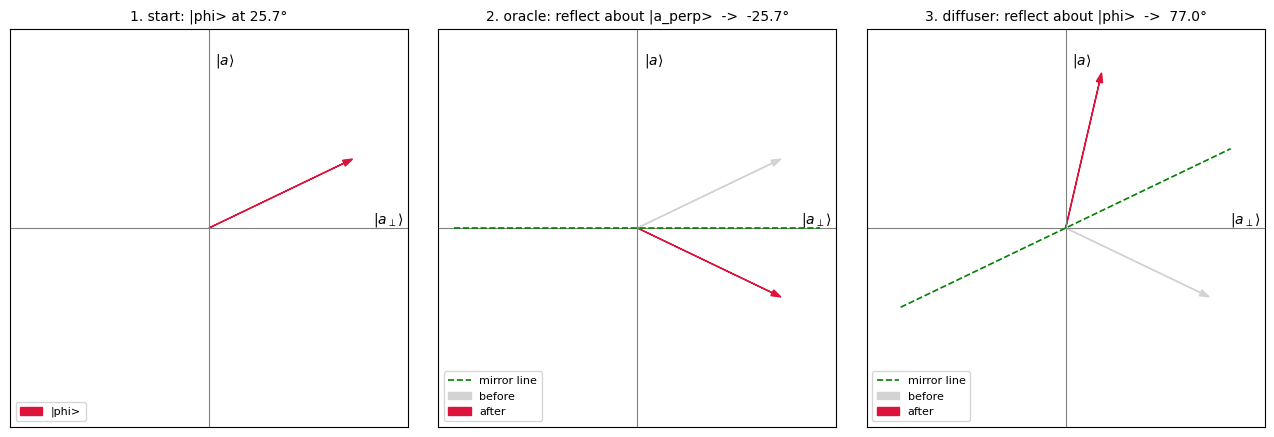

In [27]:
# The two reflections of one Grover iteration, drawn in the (|a_perp>, |a>) plane
theta = np.arcsin(np.sqrt(3 / 16))
deg = np.degrees(theta)
panels = [(f"1. start: |phi> at {deg:.1f}°",                      [theta],            None),
          (f"2. oracle: reflect about |a_perp>  ->  {-deg:.1f}°",    [theta, -theta],    0.0),
          (f"3. diffuser: reflect about |phi>  ->  {3*deg:.1f}°",  [-theta, 3*theta],  theta)]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, (title, angles, mirror) in zip(axes, panels):
    ax.set_aspect("equal"); ax.set_title(title, fontsize=10)
    ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
    ax.text(1.03, 0.03, r"$|a_\perp\rangle$"); ax.text(0.04, 1.03, r"$|a\rangle$")
    if mirror is not None:                                   # the mirror line of this reflection
        ax.plot([-1.15*np.cos(mirror), 1.15*np.cos(mirror)], [-1.15*np.sin(mirror), 1.15*np.sin(mirror)],
                color="green", ls="--", lw=1.2, label="mirror line")
    if len(angles) == 2:
        a = angles[0]
        ax.arrow(0, 0, np.cos(a), np.sin(a), head_width=0.04, color="lightgray", length_includes_head=True, label="before")
    a = angles[-1]
    ax.arrow(0, 0, np.cos(a), np.sin(a), head_width=0.04, color="crimson", length_includes_head=True, label="after" if len(angles) == 2 else "|phi>")
    ax.set_xlim(-1.25, 1.25); ax.set_ylim(-1.25, 1.25); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

**The derivation.**

**The oracle** leaves $|a_\perp\rangle$ alone and flips $|a\rangle$, so it is the reflection about the $|a_\perp\rangle$ axis:

$$
V|\psi(\alpha)\rangle = \cos\alpha\,|a_\perp\rangle - \sin\alpha\,|a\rangle = |\psi(-\alpha)\rangle .
$$

**The diffuser** $W = 2|\phi\rangle\langle\phi| - I$ is the reflection about the line through $|\phi\rangle$: it keeps the component along $|\phi\rangle$ and flips the component perpendicular to it.

Reflecting the direction $-\alpha$ about the direction $\theta$ gives $2\theta - (-\alpha) = 2\theta + \alpha$:

$$
W V|\psi(\alpha)\rangle = |\psi(\alpha + 2\theta)\rangle .
$$

Two reflections about lines at angle $\theta$ to each other always compose to a rotation by $2\theta$.

Starting from $\alpha = \theta$, after $k$ iterations

$$
(WV)^k|\phi\rangle = \cos\big((2k{+}1)\theta\big)|a_\perp\rangle + \sin\big((2k{+}1)\theta\big)|a\rangle,
$$

and measuring gives a solution with probability $\sin^2\big((2k{+}1)\theta\big)$, which is the formula of Part 6.

---

*Why does the X-sandwiched MCZ realise $2|0\rangle\langle 0| - I$ up to a sign?*

Flipping only $|0\dots0\rangle$ is $I - 2|0\rangle\langle 0|$; multiplying by the global phase $-1$ gives $2|0\rangle\langle 0| - I$.

Global phases are unobservable, so the circuit is a valid diffuser — and the check functions compare operators only up to a global phase for the same reason.

---